# Machine Learning Model Performance Evaluation

This notebook uses a **generic, synthetic customer dataset** to demonstrate classification metrics, then creates a small synthetic regression target to demonstrate regression metrics. The CSV is illustrative—not real customer data.

**Metrics covered:** Accuracy, confusion matrix, precision, recall, ROC curve/AUC, log-loss, Mean Absolute Deviation (reported as mean absolute error), coefficient of determination (R²), and error-distribution plots.

Run the cells from top to bottom. If needed, install packages with `pip install numpy pandas matplotlib scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, roc_curve, roc_auc_score, log_loss,
    mean_absolute_error, r2_score
)
from sklearn.datasets import make_regression

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## 1. Load and inspect the dataset

In [3]:
# Keep the CSV in the same folder as this notebook.
df = pd.read_csv("generic_customer_churn_dataset.csv")

display(df.head())
print("Dataset shape:", df.shape)
print("\nMissing values per column:")
display(df.isna().sum().to_frame("missing_values"))
print("\nChurn class counts (0 = stayed, 1 = churned):")
display(df["churn"].value_counts().sort_index().rename(index={0: "Stayed", 1: "Churned"}))


,customer_id,tenure_months,monthly_spend,data_usage_gb,support_calls_3m,late_payments_12m,contract_type,region,payment_method,churn
0,CUST0001,1,38.63,5.05,3,1,Two-year,West,Card,0
1,CUST0002,24,26.90,30.95,6,2,Monthly,North,Bank transfer,1
2,CUST0003,29,24.11,23.30,0,2,Annual,West,Card,1
3,CUST0004,27,10.00,31.17,0,2,Monthly,East,Digital wallet,1
4,CUST0005,22,36.97,41.03,4,3,Monthly,West,Card,1


Dataset shape: (1200, 10)

Missing values per column:


,missing_values
customer_id,0
tenure_months,0
monthly_spend,0
data_usage_gb,0
support_calls_3m,0
late_payments_12m,0
contract_type,0
region,0
payment_method,0
churn,0



Churn class counts (0 = stayed, 1 = churned):


,count
churn,
Stayed,791
Churned,409


## 2. Prepare features and train a classification model

In [4]:
# Customer ID is an identifier, so it is excluded from model features.
X = df.drop(columns=["customer_id", "churn"])
y = df["churn"]

numeric_features = [
    "tenure_months", "monthly_spend", "data_usage_gb",
    "support_calls_3m", "late_payments_12m"
]
categorical_features = ["contract_type", "region", "payment_method"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)
y_prob = classifier.predict_proba(X_test)[:, 1]


## 3. Calculate classification metrics

In [5]:
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
probabilities = classifier.predict_proba(X_test)
model_log_loss = log_loss(y_test, probabilities, labels=[0, 1])

print("CLASSIFICATION MODEL EVALUATION")
print("=" * 42)
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\nConfusion matrix (rows = actual; columns = predicted):")
display(pd.DataFrame(
    cm,
    index=["Actual stayed (0)", "Actual churned (1)"],
    columns=["Predicted stayed (0)", "Predicted churned (1)"]
))
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"Log-loss  : {model_log_loss:.4f}")


CLASSIFICATION MODEL EVALUATION
Accuracy  : 0.7208 (72.08%)

Confusion matrix (rows = actual; columns = predicted):


,Predicted stayed (0),Predicted churned (1)
Actual stayed (0),148,10
Actual churned (1),57,25


Precision : 0.7143
Recall    : 0.3049
ROC-AUC   : 0.6515
Log-loss  : 0.6056


## 4. Confusion matrix plot

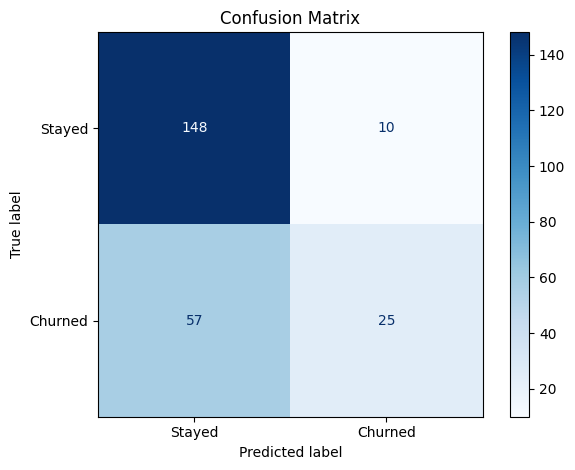

In [6]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


## 5. ROC curve

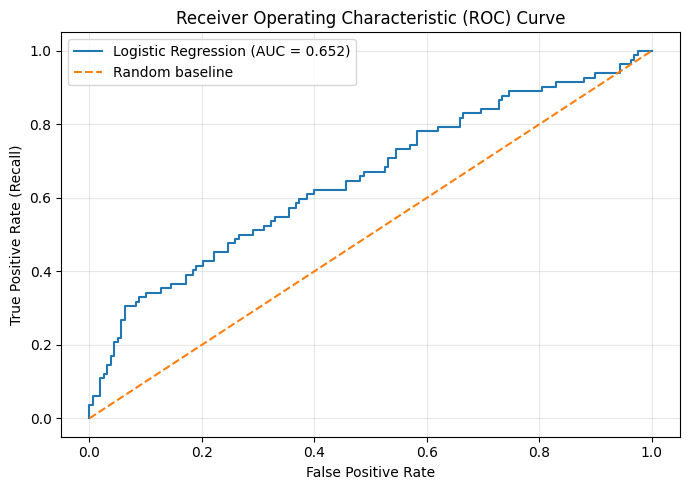

In [7]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Regression metrics and error distribution

Classification metrics above use the customer churn target. The following section creates a separate **synthetic numeric regression dataset** so that Mean Absolute Deviation/Absolute Error and R² are demonstrated appropriately. This avoids treating a classification label as a continuous target.

In [8]:
X_reg, y_reg = make_regression(
    n_samples=1000,
    n_features=6,
    n_informative=5,
    noise=18.0,
    random_state=RANDOM_STATE
)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

regressor = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
regressor.fit(X_train_r, y_train_r)
y_pred_r = regressor.predict(X_test_r)

# MAD here is the mean absolute deviation of predictions from actual values,
# commonly reported as Mean Absolute Error (MAE).
mad = mean_absolute_error(y_test_r, y_pred_r)
r_squared = r2_score(y_test_r, y_pred_r)
errors = y_test_r - y_pred_r

print("REGRESSION MODEL EVALUATION")
print("=" * 42)
print(f"Mean Absolute Deviation / Error (MAE): {mad:.4f}")
print(f"Coefficient of Determination (R²)   : {r_squared:.4f}")


REGRESSION MODEL EVALUATION
Mean Absolute Deviation / Error (MAE): 14.6956
Coefficient of Determination (R²)   : 0.9653


### Actual vs predicted values

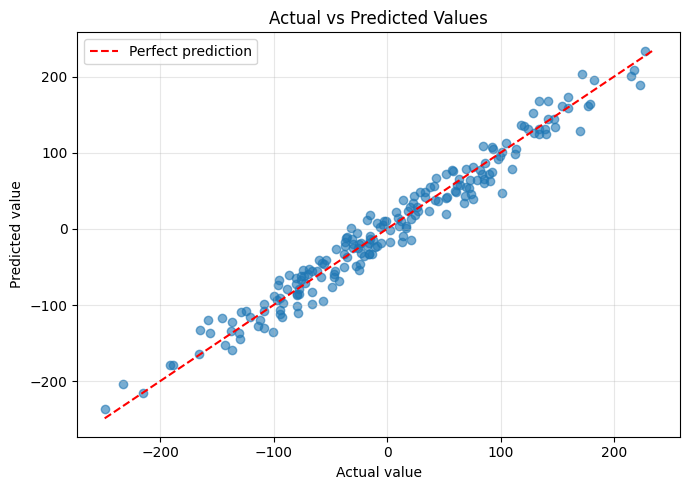

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_r, y_pred_r, alpha=0.6)
low = min(y_test_r.min(), y_pred_r.min())
high = max(y_test_r.max(), y_pred_r.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")
plt.xlabel("Actual value")
plt.ylabel("Predicted value")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Distribution of prediction errors

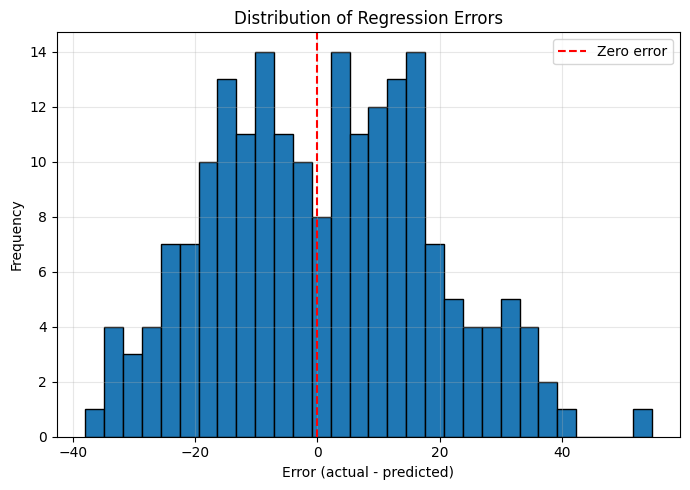

In [10]:
plt.figure(figsize=(7, 5))
plt.hist(errors, bins=30, edgecolor="black")
plt.axvline(0, color="red", linestyle="--", label="Zero error")
plt.xlabel("Error (actual - predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Regression Errors")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Residuals vs predicted values

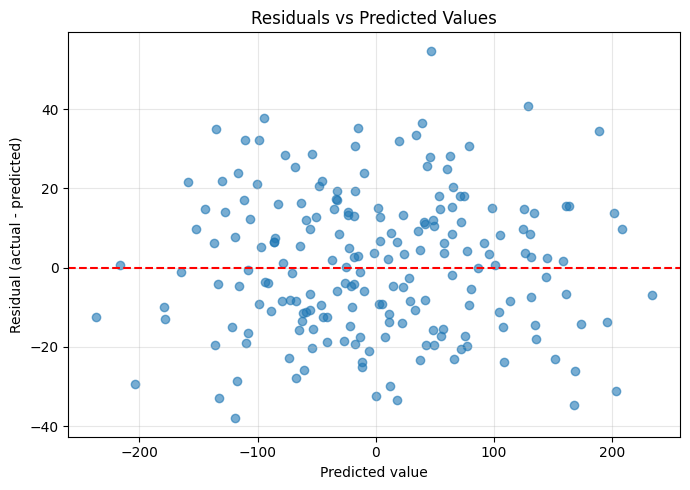

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(y_pred_r, errors, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted value")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals vs Predicted Values")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Brief interpretation

- **Accuracy:** fraction of classification predictions that are correct.
- **Confusion matrix:** counts correct and incorrect predictions for each class.
- **Precision:** among predicted churn cases, the fraction that truly churned.
- **Recall:** among actual churn cases, the fraction identified by the model.
- **ROC curve/AUC:** shows discrimination across classification thresholds; AUC closer to 1 is generally better.
- **Log-loss:** penalizes incorrect predicted probabilities; lower is better.
- **MAE/MAD:** average absolute regression error, in the target's units; lower is better.
- **R²:** proportion of target variation explained by the regression model; 1 is perfect, 0 is the test-set mean baseline, and negative values can occur.
- **Error distribution:** errors concentrated around zero with no strong pattern are often desirable.

**Important:** the customer churn data is synthetic and intended for learning. It should not be used to make real business decisions.